# 第7章 混合快速储能的功率分配

采用自建合成输入与常效率模型。依次运行5个单元，完成手算、冻结策略比较、独立能量账、绘图与参数实验。完整训练命令见README；本Notebook读取已验证的参考Q表，避免每次课堂重跑训练。

## 1 从电压到可用能量

电压平方决定内部储能。半个可用窗口对应126.49 V。

In [1]:
from pathlib import Path
import sys, json, io
import numpy as np
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapters/ch07/model.py").exists())
chapter = root / "chapters/ch07"
sys.path.insert(0, str(chapter))
from model import Config, HybridEnv, simulate, metrics
c = Config()
print("能量下限 / 上限 / 可用容量 (kWh):", c.sc_min, c.sc_max, c.sc_span)
print("能量中点电压 (V):", np.sqrt(c.sc_target * 7.2e6 / c.capacitance_f))
print("中点100 kW放电持续时间 (s):", c.sc_span / 2 * c.sc_eta / 100 * 3600)
assert abs(c.sc_span - 1.2) < 1e-10

能量下限 / 上限 / 可用容量 (kWh): 0.4 1.6 1.2000000000000002
能量中点电压 (V): 126.49110640673517
中点100 kW放电持续时间 (s): 21.168000000000003


## 2 用同一输入比较三类控制器

Q表由验证集选出。此处固定测试输入30000，读取当前观测、执行公共物理约束。

In [2]:
ex = json.loads((chapter / "reference_results/experiment.json").read_text())
q = np.array(ex["selected_q"])
traces = {m: simulate(m, 30000, q=q) for m in ["lowpass", "optimizer", "qlearning"]}
for name, rows in traces.items():
    z = metrics(rows, c)
    print(name, {k: round(z[k], 5) for k in ["rmse_kw", "battery_throughput_kwh", "sc_endpoint_kwh"]})
assert all(len(rows) == 600 for rows in traces.values())

lowpass {'rmse_kw': 0.0, 'battery_throughput_kwh': 3.39212, 'sc_endpoint_kwh': 0.03617}
optimizer {'rmse_kw': 2.05263, 'battery_throughput_kwh': 2.8268, 'sc_endpoint_kwh': -0.4644}
qlearning {'rmse_kw': 0.40759, 'battery_throughput_kwh': 4.77787, 'sc_endpoint_kwh': -0.00806}


## 3 从执行日志独立核验能量账

转换损耗和库存变化共同闭合母线能量；主动构造500 kW请求以检查残差保留。

In [3]:
from verify import audit
for name, rows in traces.items():
    result = audit(rows, c)
    print(name, "能量平衡残差 (kWh):", result["total_balance_kwh"])
env = HybridEnv(c)
env.reset(profile=[500.0])
_, _, terminated, truncated, row = env.step(500.0)
print("500 kW请求的电池/电容/残差 (kW):", row["battery_kw"], row["sc_kw"], row["residual_kw"])
assert row["residual_kw"] == 390.0
assert truncated and not terminated

lowpass 能量平衡残差 (kWh): 1.0630385460785874e-14
optimizer 能量平衡残差 (kWh): 2.8255175976710234e-14
qlearning 能量平衡残差 (kWh): 3.042011087472929e-14
500 kW请求的电池/电容/残差 (kW): 10.0 100.0 390.0


## 4 绘制当前计算结果

同轴显示电池输出与电容库存。颜色表示方法，横轴为秒。

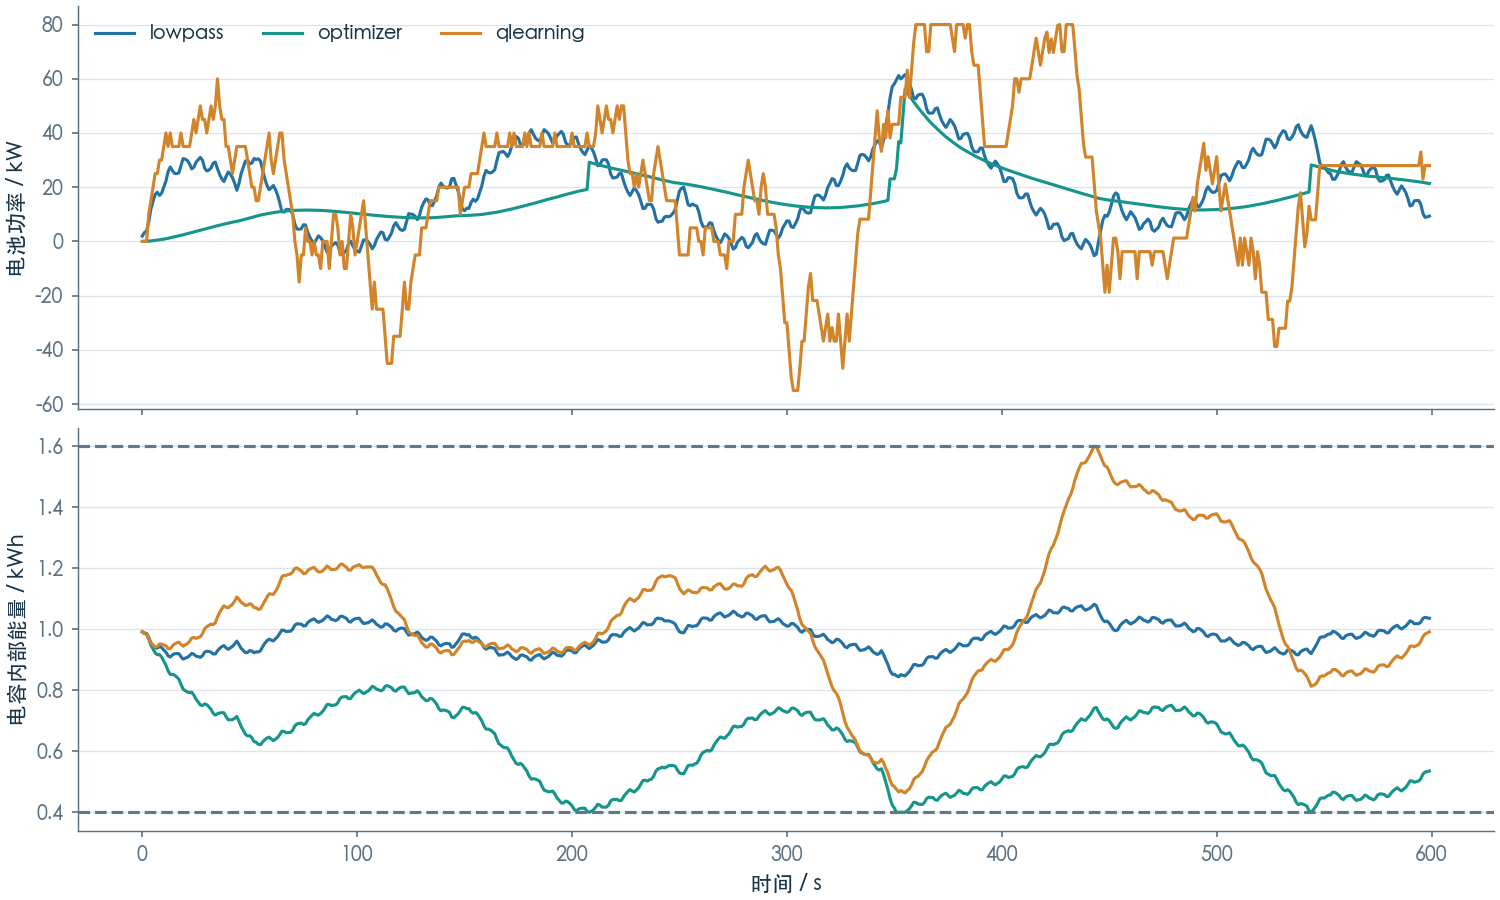

In [4]:
from visual_style import setup, plt, style
from IPython.display import Image, display
setup()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
for (name, rows), col in zip(traces.items(), ["#2471a3", "#15958b", "#d18429"]):
    t = [r["time_s"] for r in rows]
    axes[0].plot(t, [r["battery_kw"] for r in rows], color=col, label=name)
    axes[1].plot(t, [r["sc_kwh"] for r in rows], color=col)
axes[0].set_ylabel("电池功率 / kW")
axes[0].legend(frameon=False, ncol=3)
axes[1].set(xlabel="时间 / s", ylabel="电容内部能量 / kWh")
axes[1].axhline(c.sc_min, linestyle="--", color="#607887")
axes[1].axhline(c.sc_max, linestyle="--", color="#607887")
for ax in axes: style(ax)
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=150)
plt.close(fig)
display(Image(data=buffer.getvalue()))

## 5 参数实验：平滑程度与库存占用

相同输入下只改变时间常数，记录电池变化率与电容摆幅。

In [5]:
for tau in [5, 15, 45]:
    cfg = Config(tau_s=tau)
    rows = simulate("lowpass", 30000, c=cfg)
    z = metrics(rows, cfg)
    span = np.ptp([r["sc_kwh"] for r in rows])
    print(f"tau={tau:2d} s | ramp RMS={z['ramp_rms_kw_s']:.3f} kW/s | energy span={span:.3f} kWh")
print("独立交互页面：demo/ch07/教学演示.html；可导出CSV和SVG。")

tau= 5 s | ramp RMS=4.470 kW/s | energy span=0.110 kWh
tau=15 s | ramp RMS=1.749 kW/s | energy span=0.238 kWh
tau=45 s | ramp RMS=0.795 kW/s | energy span=0.358 kWh
独立交互页面：demo/ch07/教学演示.html；可导出CSV和SVG。


## 后续练习

延长测试窗口、改进状态表示或加入共同终端库存条件，分别保存配置和全部随机种子结果。吞吐量描述运行负担；寿命研究需要独立退化模型与数据。